In [1]:
import pandas as pd
from tabulate import tabulate

def print_metadata_table(df: pd.DataFrame) -> None:
	headers = ["Column", "Dtype", "Nulls", "Mean/Median/Mode",
				"Min/Max", "Std/Variance", "Unique/Top3"]
	rows = []

	for col in df.columns:
		series = df[col]
		dtype = str(series.dtype)
		null_count = int(series.isna().sum())

		if pd.api.types.is_numeric_dtype(series):
			mean_median_mode = f"mean={series.mean():.2f}\nmedian={series.median():.2f}"
			min_max = f"min={series.min():.2f}\nmax={series.max():.2f}"
			std_var = f"std={series.std():.2f}\nvariance={series.var():.2f}"
			unique_top3 = "-"
		else:
			value_counts = series.value_counts()  # already sorted desc by count
			unique_count = int(series.nunique())
			mode = value_counts.index[0] if not value_counts.empty else "-"
			top3 = "\n  ".join(f"{name}: {count}" for name, count in value_counts.head(3).items())

			mean_median_mode = f"{'mean':<8}={series.mean():.2f}\n{'median':<8}={series.median():.2f}"
			min_max = f"{'min':<8}={series.min():.2f}\n{'max':<8}={series.max():.2f}"
			std_var = f"{'std':<8}={series.std():.2f}\n{'variance':<8}={series.var():.2f}"
			unique_top3 = f"unique={unique_count}\ntop3:\n  {top3}"

		rows.append([col, dtype, null_count, mean_median_mode, min_max, std_var, unique_top3])

	print(f"Dataset: {df.shape[0]} rows x {df.shape[1]} columns")
	print(tabulate(
	rows, headers=headers, tablefmt="fancy_grid",
	colalign=("left", "left", "right", "right", "right", "right", "left")
	))


df = pd.read_csv('/home/kartikag234/Documents/rusmlai/tests/fixtures/kaggle_playground-series-s6e1/train.csv')
print_metadata_table(df)

TypeError: Cannot perform reduction 'mean' with string dtype

DATASET OVERVIEW
Shape: (350, 9)

Missing values:
age           0
income        0
score         0
height        0
weight        0
experience    0
category      0
gender        0
region        0
dtype: int64

NUMERICAL SUMMARY (mean, median, std, min, max, quartiles)
          age     income   score  height  weight  experience
count  350.00     350.00  350.00  350.00  350.00      350.00
mean    34.08   44265.65   73.54  168.30   72.35        8.45
std      8.35   21507.61   13.23    9.12   10.83        5.18
min     18.00   11925.00   38.10  141.90   38.90        0.00
25%     27.92   28582.25   64.20  162.02   65.12        4.00
50%     34.45   39548.50   74.10  168.35   72.25        8.00
75%     39.60   53822.75   81.88  173.70   79.68       13.00
max     65.00  160411.00  100.00  191.20  106.10       17.00

CATEGORICAL SUMMARY (counts + unique)

category  |  unique = 4
category
A    100
B     98
D     79
C     73
Name: count, dtype: int64

gender  |  unique = 2
gender
Male      183
Femal

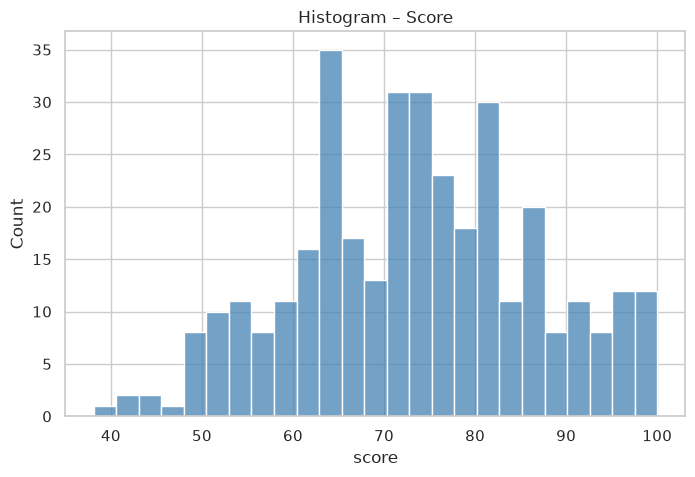

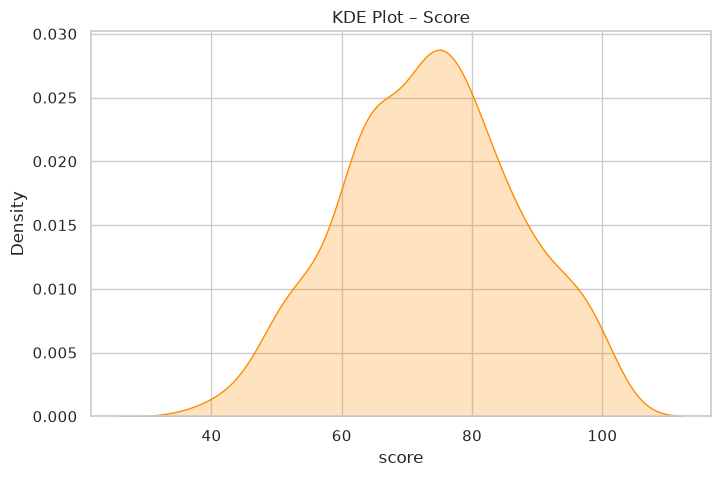

/tmp/ipykernel_79115/1644575665.py:79: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x="category", y="score", palette="Set2")


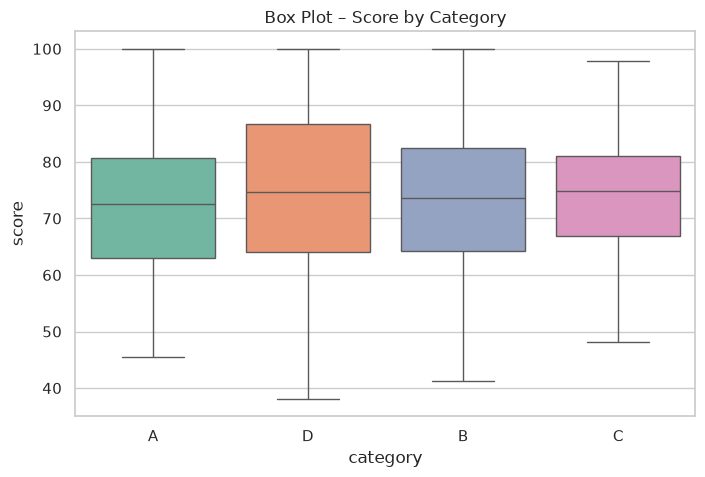

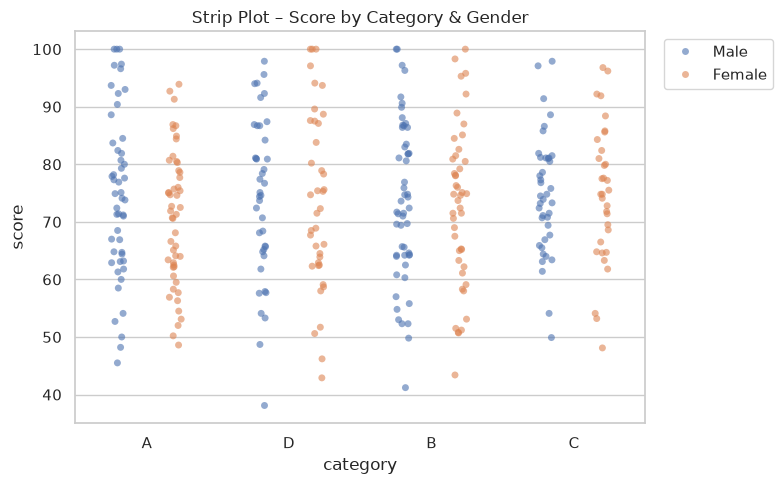

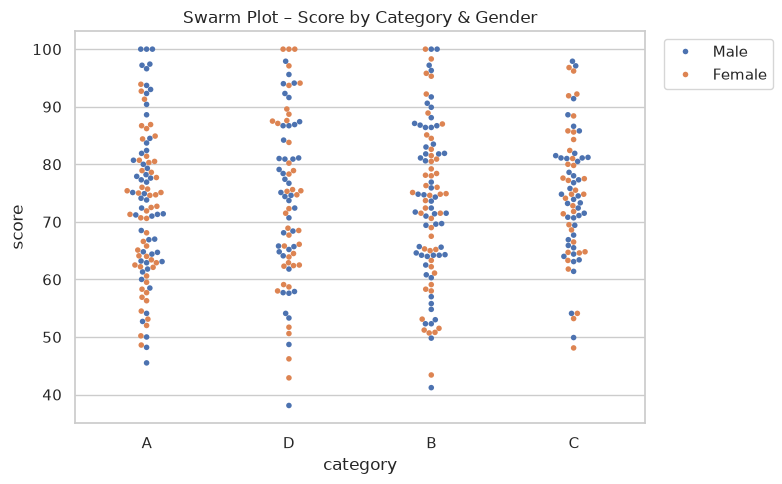

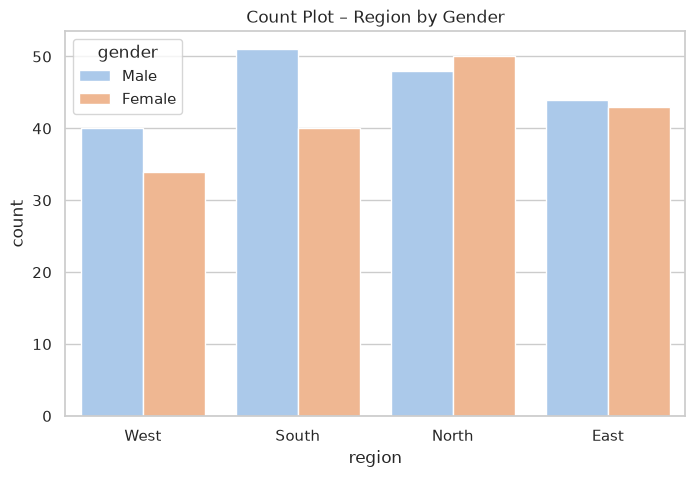

/tmp/ipykernel_79115/1644575665.py:107: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=df, x="category", y="score", estimator="mean", errorbar=("ci", 95), palette="muted")


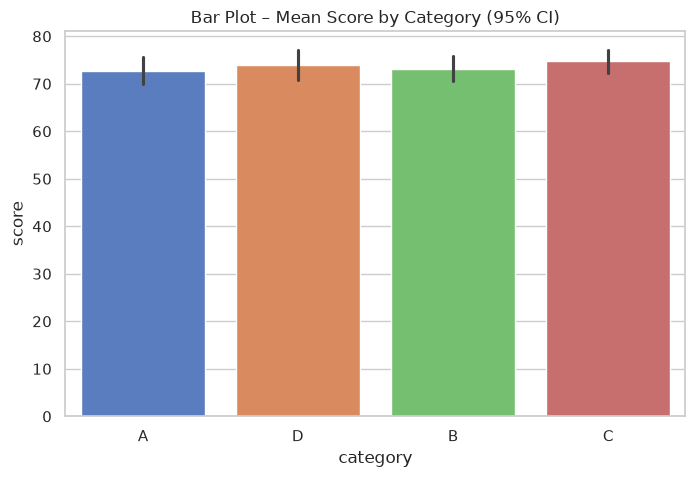

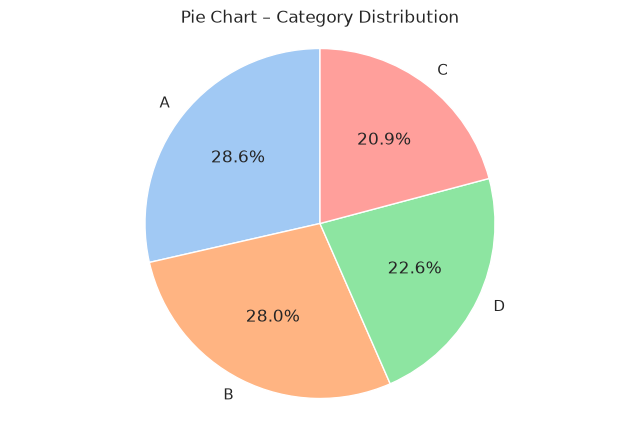

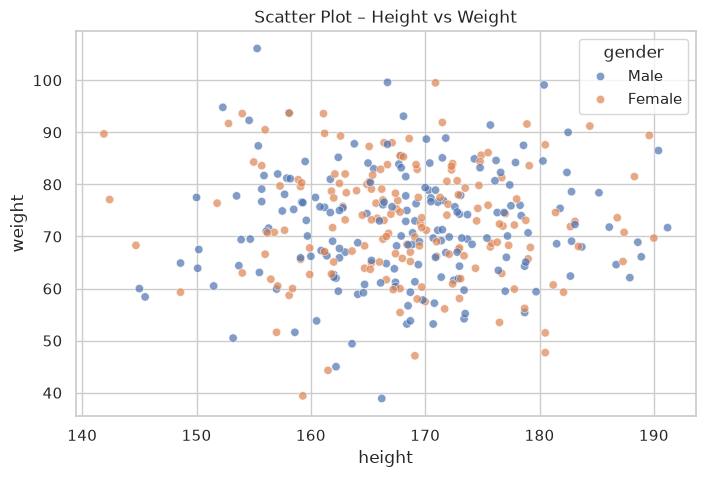

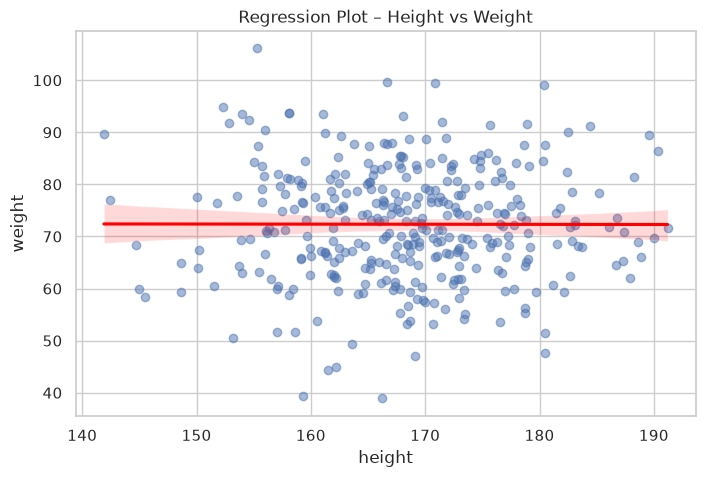

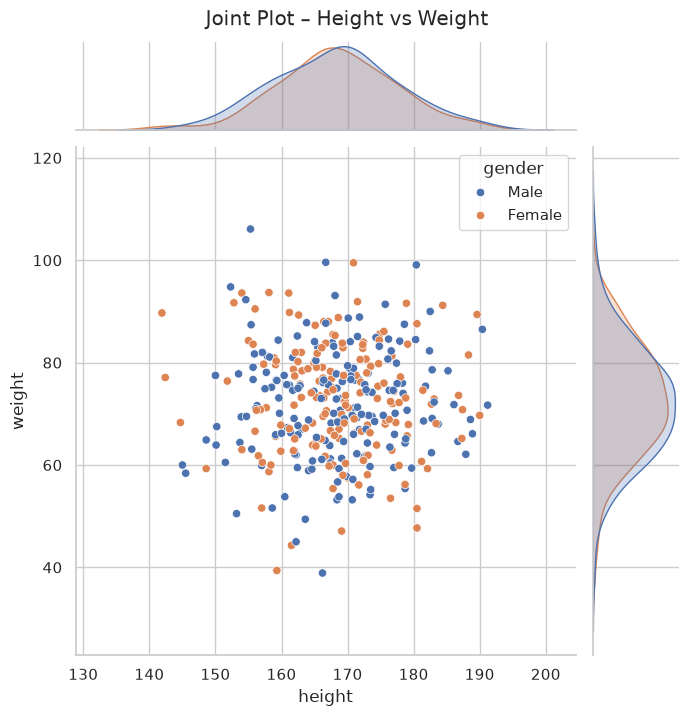

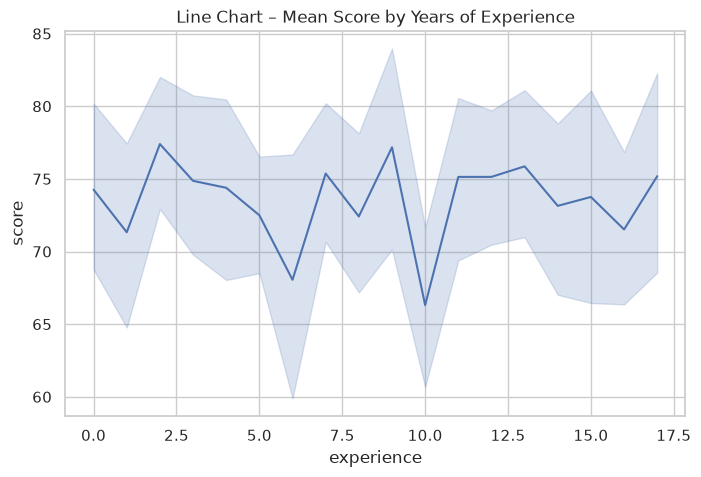

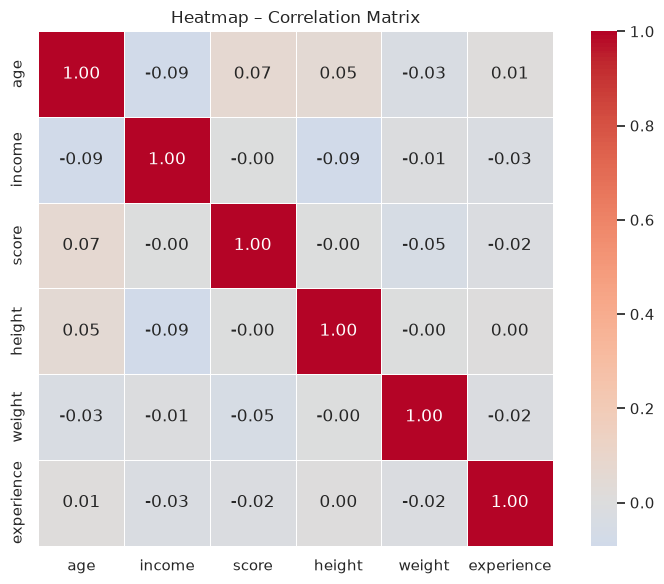

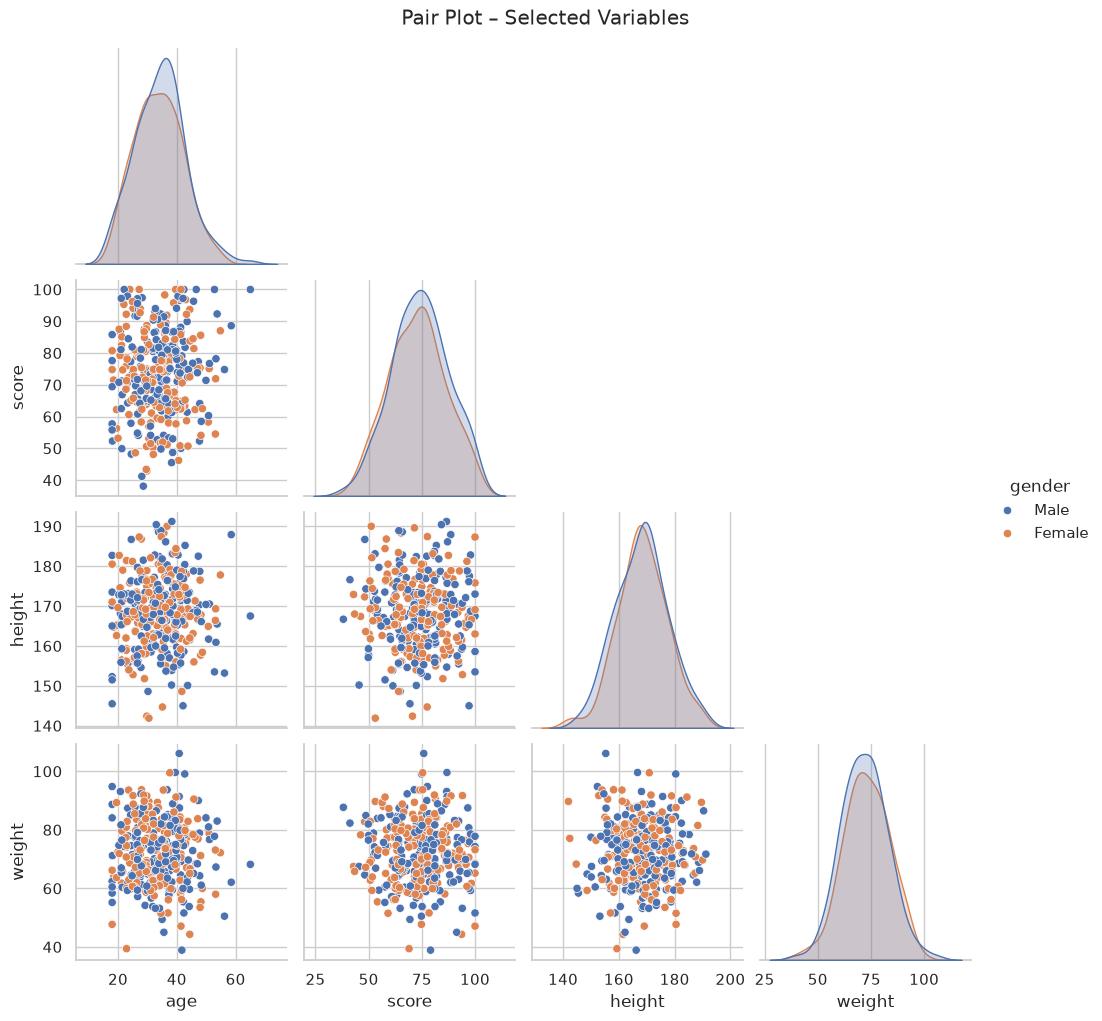


All plots generated.


In [2]:
# ============================================================
# Self-contained Jupyter notebook cell
# Synthetic data + all requested plots (pandas + matplotlib + seaborn)
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# ------------------------------------------------------------
# 1. Create reproducible synthetic dataset
# ------------------------------------------------------------
np.random.seed(42)
n = 350

df = pd.DataFrame({
    "age":        np.random.normal(34, 9, n).clip(18, 65).round(1),
    "income":     np.random.lognormal(10.6, 0.45, n).round(0),
    "score":      np.random.normal(72, 14, n).clip(0, 100).round(1),
    "height":     np.random.normal(168, 9, n).round(1),
    "weight":     np.random.normal(71, 11, n).round(1),
    "experience": np.random.randint(0, 18, n),
    "category":   np.random.choice(["A", "B", "C", "D"], n, p=[0.32, 0.28, 0.22, 0.18]),
    "gender":     np.random.choice(["Male", "Female"], n),
    "region":     np.random.choice(["North", "South", "East", "West"], n)
})

# ------------------------------------------------------------
# 2. Usual summary statistics people look at before plotting
# ------------------------------------------------------------
print("=" * 60)
print("DATASET OVERVIEW")
print("=" * 60)
print(f"Shape: {df.shape}")
print(f"\nMissing values:\n{df.isnull().sum()}")

print("\n" + "=" * 60)
print("NUMERICAL SUMMARY (mean, median, std, min, max, quartiles)")
print("=" * 60)
print(df.describe().round(2))

print("\n" + "=" * 60)
print("CATEGORICAL SUMMARY (counts + unique)")
print("=" * 60)
for col in ["category", "gender", "region"]:
    print(f"\n{col}  |  unique = {df[col].nunique()}")
    print(df[col].value_counts())

print("\n" + "=" * 60)
print("GROUPED MEANS (useful for bar / line decisions)")
print("=" * 60)
print(df.groupby("category")[["score", "income"]].agg(["mean", "median"]).round(1))

# ------------------------------------------------------------
# 3. Plotting style
# ------------------------------------------------------------
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.figsize"] = (8, 5)

# ------------------------------------------------------------
# 4. Individual plots
# ------------------------------------------------------------

# --- Histogram (distribution of a continuous variable) ---
plt.figure()
sns.histplot(data=df, x="score", bins=25, kde=False, color="steelblue")
plt.title("Histogram – Score")
plt.show()

# --- KDE plot (smoothed density) ---
plt.figure()
sns.kdeplot(data=df, x="score", fill=True, color="darkorange")
plt.title("KDE Plot – Score")
plt.show()

# --- Box plot (distribution + outliers by category) ---
plt.figure()
sns.boxplot(data=df, x="category", y="score", palette="Set2")
plt.title("Box Plot – Score by Category")
plt.show()

# --- Strip plot (individual points by category) ---
plt.figure()
sns.stripplot(data=df, x="category", y="score", hue="gender", dodge=True, alpha=0.6)
plt.title("Strip Plot – Score by Category & Gender")
plt.legend(bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.show()

# --- Swarm plot (non-overlapping points) ---
plt.figure()
sns.swarmplot(data=df, x="category", y="score", hue="gender", size=4)
plt.title("Swarm Plot – Score by Category & Gender")
plt.legend(bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.show()

# --- Count plot (frequency of categories) ---
plt.figure()
sns.countplot(data=df, x="region", hue="gender", palette="pastel")
plt.title("Count Plot – Region by Gender")
plt.show()

# --- Bar plot / Bar graph (mean of continuous by category) ---
plt.figure()
sns.barplot(data=df, x="category", y="score", estimator="mean", errorbar=("ci", 95), palette="muted")
plt.title("Bar Plot – Mean Score by Category (95% CI)")
plt.show()

# --- Pie chart (proportion of categories) ---
plt.figure()
counts = df["category"].value_counts()
plt.pie(counts, labels=counts.index, autopct="%1.1f%%", startangle=90,
        colors=sns.color_palette("pastel"))
plt.title("Pie Chart – Category Distribution")
plt.axis("equal")
plt.show()

# --- Scatter plot ---
plt.figure()
sns.scatterplot(data=df, x="height", y="weight", hue="gender", alpha=0.7)
plt.title("Scatter Plot – Height vs Weight")
plt.show()

# --- Regression plot (scatter + linear fit) ---
plt.figure()
sns.regplot(data=df, x="height", y="weight", scatter_kws={"alpha": 0.5}, line_kws={"color": "red"})
plt.title("Regression Plot – Height vs Weight")
plt.show()

# --- Joint plot (scatter + marginal histograms/KDEs) ---
sns.jointplot(data=df, x="height", y="weight", kind="scatter", hue="gender", height=7)
plt.suptitle("Joint Plot – Height vs Weight", y=1.02)
plt.show()

# --- Line chart (mean trend over an ordered variable) ---
plt.figure()
sns.lineplot(data=df, x="experience", y="score", estimator="mean", errorbar=("ci", 95))
plt.title("Line Chart – Mean Score by Years of Experience")
plt.show()

# --- Heatmap (correlation matrix) ---
num_cols = ["age", "income", "score", "height", "weight", "experience"]
corr = df[num_cols].corr()

plt.figure(figsize=(8, 6))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0,
            square=True, linewidths=0.5)
plt.title("Heatmap – Correlation Matrix")
plt.tight_layout()
plt.show()

# --- Pair plot (all pairwise relationships) ---
# Using a subset to keep it readable
pair_cols = ["age", "score", "height", "weight", "gender"]
sns.pairplot(df[pair_cols], hue="gender", corner=True, diag_kind="kde")
plt.suptitle("Pair Plot – Selected Variables", y=1.02)
plt.show()

print("\nAll plots generated.")